# DeepSense-X — Phase 6
## Final Experimental Evaluation and Comparative Analysis

**Goal:** Compare the Phase 2 LSTM Autoencoder, Phase 3 Transformer Autoencoder, and Phase 4 Hybrid LSTM–Transformer Autoencoder using identical validation and test windows.

### Evaluation plan
1. Load the three saved models and the Phase 1 dataset.
2. Recreate identical train/validation/test samples with the same random seed and sampling order used in Phases 2–4.
3. Calculate reconstruction errors for each model.
4. Calibrate a separate 99th-percentile threshold on the same validation sample for each model.
5. Evaluate precision, recall, F1, accuracy, confusion matrix, false positives and false negatives.
6. Compare event-wise detection and threshold sensitivity.
7. Save tables, plots and final metadata.

> Research safeguards: thresholds are calibrated on validation data, not test labels. The three models are evaluated on the same sampled windows. Event-window recall measures detection during labelled event periods; it does not establish advance failure prediction. These are sampled experiments, not full-test-set results.

## 1. Mount Drive and define paths

If any model path does not exist, stop and share the output. Do not retrain or overwrite any model.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    confusion_matrix, classification_report
)

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

ROOT = '/content/drive/MyDrive/DeepSense_X_MetroPT3'
DATA_PATH = os.path.join(ROOT, 'processed', 'metropt3_phase1_windows.npz')
LSTM_PATH = os.path.join(ROOT, 'artifacts', 'phase2_lstm_autoencoder_final.keras')
TRANSFORMER_PATH = os.path.join(ROOT, 'artifacts', 'phase3_transformer_autoencoder_final.keras')
HYBRID_PATH = os.path.join(ROOT, 'artifacts', 'phase4_hybrid_lstm_transformer_final.keras')
OUT_DIR = os.path.join(ROOT, 'phase6')
os.makedirs(OUT_DIR, exist_ok=True)

paths = {
    'Phase 1 dataset': DATA_PATH,
    'Phase 2 LSTM': LSTM_PATH,
    'Phase 3 Transformer': TRANSFORMER_PATH,
    'Phase 4 Hybrid': HYBRID_PATH
}
for name, path in paths.items():
    print(('FOUND  ' if os.path.exists(path) else 'MISSING ') + name + ': ' + path)

Mounted at /content/drive
FOUND  Phase 1 dataset: /content/drive/MyDrive/DeepSense_X_MetroPT3/processed/metropt3_phase1_windows.npz
FOUND  Phase 2 LSTM: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase2_lstm_autoencoder_final.keras
FOUND  Phase 3 Transformer: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase3_transformer_autoencoder_final.keras
FOUND  Phase 4 Hybrid: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase4_hybrid_lstm_transformer_final.keras


## 2. Load Phase 1 data and reproduce identical samples

This uses the same seed, sample sizes, and sampling order used in the earlier model notebooks: train 5,000, validation 2,000, test 10,000.

In [2]:
data = np.load(DATA_PATH, allow_pickle=True)
X_train_all = data['X_train']
X_val_all = data['X_val']
X_test_all = data['X_test']
y_test_event_all = data['y_test_event']

rng = np.random.default_rng(SEED)
train_idx = rng.choice(len(X_train_all), size=min(5000, len(X_train_all)), replace=False)
val_idx = rng.choice(len(X_val_all), size=min(2000, len(X_val_all)), replace=False)
test_idx = rng.choice(len(X_test_all), size=min(10000, len(X_test_all)), replace=False)

X_train = X_train_all[train_idx].astype('float32')
X_val = X_val_all[val_idx].astype('float32')
X_test = X_test_all[test_idx].astype('float32')
y_test_event = y_test_event_all[test_idx].astype(int)

print('Train:', X_train.shape)
print('Validation:', X_val.shape)
print('Test:', X_test.shape)
print('Event-labelled test windows:', int(y_test_event.sum()))

Train: (5000, 60, 13)
Validation: (2000, 60, 13)
Test: (10000, 60, 13)
Event-labelled test windows: 516


## 3. Define compatibility classes for saved positional embeddings

The Phase 4 archive stores its position vector as a nested `Embedding` layer. The Phase 3 Transformer notebook may have saved a direct trainable position vector. These two compatibility classes preserve the respective weight layouts.

In [6]:

@keras.utils.register_keras_serializable(package='DeepSenseX')
class Phase3PositionEmbedding(keras.layers.Layer):

    def __init__(self, sequence_length=None, embed_dim=None, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embed_dim = embed_dim

        self.embedding = keras.layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim,
            name='embedding'
        )

    def call(self, inputs):
        positions = tf.range(
            start=0,
            limit=self.sequence_length,
            delta=1
        )
        position_values = self.embedding(positions)
        return inputs + tf.expand_dims(position_values, axis=0)

    def get_config(self):
        config = super().get_config()
        config.update({
            'sequence_length': self.sequence_length,
            'embed_dim': self.embed_dim
        })
        return config


In [5]:

import zipfile
import h5py
import os

print("Transformer model exists:", os.path.exists(TRANSFORMER_PATH))

with zipfile.ZipFile(TRANSFORMER_PATH, 'r') as z:
    print("\nModel archive files:")
    print(z.namelist())

    z.extract('model.weights.h5', '/content/phase3_debug')

phase3_weights_path = '/content/phase3_debug/model.weights.h5'

print("\nPosition embedding weights:")

with h5py.File(phase3_weights_path, 'r') as f:

    def inspect_phase3(name, obj):
        if 'position_embedding' in name.lower():
            if isinstance(obj, h5py.Dataset):
                print(name, "Shape:", obj.shape)
            else:
                print("GROUP:", name)

    f.visititems(inspect_phase3)


Transformer model exists: True

Model archive files:
['metadata.json', 'config.json', 'model.weights.h5']

Position embedding weights:
GROUP: layers/position_embedding
GROUP: layers/position_embedding/embedding
GROUP: layers/position_embedding/embedding/vars
layers/position_embedding/embedding/vars/0 Shape: (60, 32)
GROUP: layers/position_embedding/vars


In [9]:
import traceback

try:
    transformer_model = keras.models.load_model(
        TRANSFORMER_PATH,
        custom_objects={
            'PositionEmbedding': Phase3PositionEmbedding,
            'DeepSenseX>PositionEmbedding': Phase3PositionEmbedding
        },
        compile=False
    )

    print("Transformer model loaded successfully!")
    print("Input:", transformer_model.input_shape)
    print("Output:", transformer_model.output_shape)

except Exception as e:
    print("ERROR TYPE:", type(e).__name__)
    print("ERROR MESSAGE:", str(e))
    traceback.print_exc()

ERROR TYPE: ValueError
ERROR MESSAGE: A total of 1 objects could not be loaded. Example error message for object <Embedding name=embedding, built=True>:

Layer 'embedding' expected 1 variables, but received 0 variables during loading. Expected: ['embeddings']

List of objects that could not be loaded:
[<Embedding name=embedding, built=True>]


Traceback (most recent call last):
  File "/tmp/ipykernel_461/1793330361.py", line 4, in <cell line: 0>
    transformer_model = keras.models.load_model(
        TRANSFORMER_PATH,
    ...<4 lines>...
        compile=False
    )
  File "/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_api.py", line 189, in load_model
    return saving_lib.load_model(
           ~~~~~~~~~~~~~~~~~~~~~^
        filepath,
        ^^^^^^^^^
    ...<2 lines>...
        safe_mode=safe_mode,
        ^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py", line 365, in load_model
    return _load_model_from_fileobj(
        f, custom_objects, compile, safe_mode
    )
  File "/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py", line 507, in _load_model_from_fileobj
    _raise_loading_failure(error_msgs)
    ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py", li

In [10]:
import zipfile
import json
import h5py
import os

print("TRANSFORMER PATH:", TRANSFORMER_PATH)

with zipfile.ZipFile(TRANSFORMER_PATH, "r") as z:

    # Inspect model configuration
    config = json.loads(z.read("config.json"))

    print("\n--- POSITION EMBEDDING CONFIG ---")

    def find_position_layer(obj):
        if isinstance(obj, dict):
            if "class_name" in obj and "PositionEmbedding" in str(obj.get("class_name")):
                print(json.dumps(obj, indent=2))

            for value in obj.values():
                find_position_layer(value)

        elif isinstance(obj, list):
            for value in obj:
                find_position_layer(value)

    find_position_layer(config)

    # Inspect saved weights
    z.extract("model.weights.h5", "/content/phase3_debug")

weights_path = "/content/phase3_debug/model.weights.h5"

print("\n--- COMPLETE POSITION EMBEDDING WEIGHT DETAILS ---")

with h5py.File(weights_path, "r") as f:

    def inspect(name, obj):
        if "position_embedding" in name.lower():
            print("\n", name)

            if isinstance(obj, h5py.Dataset):
                print("Shape:", obj.shape)
                print("Value sample:", obj[()].flatten()[:5])

            elif isinstance(obj, h5py.Group):
                print("Attributes:", dict(obj.attrs))

    f.visititems(inspect)

TRANSFORMER PATH: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase3_transformer_autoencoder_final.keras

--- POSITION EMBEDDING CONFIG ---
{
  "module": null,
  "class_name": "PositionEmbedding",
  "config": {
    "name": "position_embedding",
    "sequence_length": 60,
    "embed_dim": 32,
    "trainable": true,
    "dtype": {
      "module": "keras",
      "class_name": "DTypePolicy",
      "config": {
        "name": "float32"
      },
      "registered_name": null,
      "shared_object_id": 136986588553536
    }
  },
  "registered_name": "PositionEmbedding",
  "build_config": {
    "input_shape": [
      null,
      60,
      32
    ]
  },
  "name": "position_embedding",
  "inbound_nodes": [
    {
      "args": [
        {
          "class_name": "__keras_tensor__",
          "config": {
            "shape": [
              null,
              60,
              32
            ],
            "dtype": "float32",
            "keras_history": [
              "input_projectio

In [11]:

@keras.utils.register_keras_serializable()
class Phase3PositionEmbedding(keras.layers.Layer):

    def __init__(self, sequence_length=None, embed_dim=None, **kwargs):
        super().__init__(**kwargs)

        self.sequence_length = sequence_length
        self.embed_dim = embed_dim

        self.embedding = keras.layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim,
            name="embedding"
        )

    def build(self, input_shape):
        # Explicitly create the child Embedding weights
        if not self.embedding.built:
            self.embedding.build((None,))

        super().build(input_shape)

    def call(self, inputs):
        positions = tf.range(
            start=0,
            limit=self.sequence_length,
            delta=1
        )

        position_values = self.embedding(positions)

        return inputs + tf.expand_dims(position_values, axis=0)

    def get_config(self):
        config = super().get_config()

        config.update({
            "sequence_length": self.sequence_length,
            "embed_dim": self.embed_dim
        })

        return config


In [17]:
import zipfile
import h5py
import shutil

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

print("\n--- PHASE 4 CLASS DETAILS ---")
print("Class:", Phase4PositionEmbedding)
print("Module:", Phase4PositionEmbedding.__module__)
print("Methods:", [
    name for name in dir(Phase4PositionEmbedding)
    if name in ["build", "call", "get_config", "__init__"]
])

print("\n--- PHASE 3 SAVED WEIGHT STRUCTURE ---")

with zipfile.ZipFile(TRANSFORMER_PATH, "r") as z:
    with z.open("model.weights.h5") as source:
        with open("/content/phase3_weights_debug.h5", "wb") as target:
            shutil.copyfileobj(source, target)

with h5py.File("/content/phase3_weights_debug.h5", "r") as f:

    group = f["layers/position_embedding"]

    def show_tree(name, obj):
        if isinstance(obj, h5py.Group):
            print("GROUP:", name, "| Attributes:", dict(obj.attrs))
        else:
            print("WEIGHT:", name, "| Shape:", obj.shape)

    group.visititems(show_tree)

TensorFlow: 2.21.0
Keras: 3.13.2

--- PHASE 4 CLASS DETAILS ---
Class: <class '__main__.Phase4PositionEmbedding'>
Module: __main__
Methods: ['__init__', 'build', 'call', 'get_config']

--- PHASE 3 SAVED WEIGHT STRUCTURE ---
GROUP: embedding | Attributes: {}
GROUP: embedding/vars | Attributes: {'name': 'embedding'}
WEIGHT: embedding/vars/0 | Shape: (60, 32)
GROUP: vars | Attributes: {'name': 'position_embedding'}


In [18]:
# Create a standalone Phase 4 positional embedding layer
test_layer = Phase4PositionEmbedding(
    sequence_length=60,
    embed_dim=32
)

# Build it with the same input shape as Phase 3
test_layer.build((None, 60, 32))

print("Parent layer built:", test_layer.built)
print("Child embedding built:", test_layer.embedding.built)

print("\nChild embedding weights:")
for weight in test_layer.embedding.weights:
    print("Name:", weight.name)
    print("Shape:", weight.shape)
    print("Path:", weight.path)

print("\nParent layer weights:")
for weight in test_layer.weights:
    print("Name:", weight.name)
    print("Shape:", weight.shape)
    print("Path:", weight.path)

Parent layer built: True
Child embedding built: False

Child embedding weights:

Parent layer weights:


In [19]:
class Phase3PositionEmbeddingFixed(keras.layers.Layer):

    def __init__(self, sequence_length=None, embed_dim=None, **kwargs):
        super().__init__(**kwargs)

        self.sequence_length = sequence_length
        self.embed_dim = embed_dim

        self.embedding = keras.layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim,
            name="embedding"
        )

    def build(self, input_shape):
        # Explicitly build the child layer before the parent
        self.embedding.build((None,))

        super().build(input_shape)

    def call(self, inputs):
        positions = tf.range(self.sequence_length)
        position_values = self.embedding(positions)

        return inputs + tf.expand_dims(position_values, axis=0)

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "embed_dim": self.embed_dim
        })
        return config

In [20]:
test_layer = Phase3PositionEmbeddingFixed(
    sequence_length=60,
    embed_dim=32
)

test_layer.build((None, 60, 32))

print("Parent built:", test_layer.built)
print("Child built:", test_layer.embedding.built)

print("\nWeights:")
for weight in test_layer.weights:
    print(weight.name, weight.shape)

Parent built: True
Child built: True

Weights:
embeddings (60, 32)


In [26]:
@keras.utils.register_keras_serializable(package='DeepSenseX')
class Phase4PositionEmbedding(keras.layers.Layer):

    def __init__(self, sequence_length=None, embed_dim=None, **kwargs):
        super().__init__(**kwargs)

        self.sequence_length = sequence_length
        self.embed_dim = embed_dim

        self.embedding = keras.layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim,
            name='embedding'
        )

    def call(self, inputs):
        positions = tf.range(
            start=0,
            limit=self.sequence_length,
            delta=1
        )

        position_values = self.embedding(positions)

        return inputs + tf.expand_dims(position_values, axis=0)

    def get_config(self):
        config = super().get_config()

        config.update({
            'sequence_length': self.sequence_length,
            'embed_dim': self.embed_dim
        })

        return config

In [28]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
import os
import tensorflow as tf
import keras

BASE_DIR = "/content/drive/MyDrive/DeepSense_X_MetroPT3"

TRANSFORMER_PATH = os.path.join(
    BASE_DIR, "artifacts/phase3_transformer_autoencoder_final.keras"
)

HYBRID_PATH = os.path.join(
    BASE_DIR, "artifacts/phase4_hybrid_lstm_transformer_final.keras"
)

LSTM_PATH = os.path.join(
    BASE_DIR, "artifacts/phase2_lstm_autoencoder_final.keras"
)

print("LSTM exists:", os.path.exists(LSTM_PATH))
print("Transformer exists:", os.path.exists(TRANSFORMER_PATH))
print("Hybrid exists:", os.path.exists(HYBRID_PATH))

LSTM exists: True
Transformer exists: True
Hybrid exists: True


In [30]:
@keras.utils.register_keras_serializable(package='DeepSenseX')
class Phase4PositionEmbedding(keras.layers.Layer):

    def __init__(self, sequence_length=None, embed_dim=None, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embed_dim = embed_dim

        self.embedding = keras.layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim,
            name='embedding'
        )

    def call(self, inputs):
        positions = tf.range(0, self.sequence_length, 1)
        position_values = self.embedding(positions)
        return inputs + tf.expand_dims(position_values, axis=0)

    def get_config(self):
        config = super().get_config()
        config.update({
            'sequence_length': self.sequence_length,
            'embed_dim': self.embed_dim
        })
        return config

In [33]:
import zipfile
import h5py
import json

print("Hybrid file exists:", os.path.exists(HYBRID_PATH))

with zipfile.ZipFile(HYBRID_PATH, "r") as z:

    config = json.loads(z.read("config.json"))

    print("\n--- POSITION EMBEDDING CONFIG ---")

    def find_position(obj):
        if isinstance(obj, dict):
            if obj.get("class_name") == "PositionEmbedding":
                print(json.dumps(obj, indent=2))

            for value in obj.values():
                find_position(value)

        elif isinstance(obj, list):
            for value in obj:
                find_position(value)

    find_position(config)

    print("\n--- SAVED POSITION EMBEDDING WEIGHTS ---")

    with z.open("model.weights.h5") as source:
        import shutil
        with open("/content/phase4_weights_debug.h5", "wb") as target:
            shutil.copyfileobj(source, target)

with h5py.File("/content/phase4_weights_debug.h5", "r") as f:

    def inspect(name, obj):
        if "position_embedding" in name.lower():
            if isinstance(obj, h5py.Group):
                print("GROUP:", name, dict(obj.attrs))
            else:
                print("WEIGHT:", name, "Shape:", obj.shape)

    f.visititems(inspect)

Hybrid file exists: True

--- POSITION EMBEDDING CONFIG ---
{
  "module": null,
  "class_name": "PositionEmbedding",
  "config": {
    "name": "position_embedding",
    "trainable": true,
    "dtype": {
      "module": "keras",
      "class_name": "DTypePolicy",
      "config": {
        "name": "float32"
      },
      "registered_name": null,
      "shared_object_id": 135011279196176
    },
    "sequence_length": 60,
    "embed_dim": 32
  },
  "registered_name": "DeepSenseX>PositionEmbedding",
  "build_config": {
    "input_shape": [
      null,
      60,
      32
    ]
  },
  "name": "position_embedding",
  "inbound_nodes": [
    {
      "args": [
        {
          "class_name": "__keras_tensor__",
          "config": {
            "shape": [
              null,
              60,
              32
            ],
            "dtype": "float32",
            "keras_history": [
              "transformer_input_projection",
              0,
              0
            ]
          }
    

In [34]:
import json
import zipfile

with zipfile.ZipFile(HYBRID_PATH, "r") as z:
    config = json.loads(z.read("config.json"))

print("Model class:", config.get("class_name"))
print("Model name:", config.get("config", {}).get("name"))

print("\nTop-level layers:")
for layer in config["config"]["layers"]:
    print(
        layer["name"],
        "|",
        layer["class_name"]
    )

Model class: Functional
Model name: DeepSenseX_Hybrid_LSTM_Transformer

Top-level layers:
sensor_window | InputLayer
transformer_input_projection | Dense
position_embedding | PositionEmbedding
multi_head_attention | MultiHeadAttention
add | Add
layer_normalization | LayerNormalization
dense | Dense
dropout_1 | Dropout
dense_1 | Dense
add_1 | Add
lstm_sequence_branch | LSTM
layer_normalization_1 | LayerNormalization
lstm_transformer_fusion | Concatenate
fusion_projection | Dense
dropout_2 | Dropout
lstm_decoder | LSTM
reconstruction | TimeDistributed


In [35]:
import h5py

with h5py.File("/content/phase4_weights_debug.h5", "r") as f:

    def print_structure(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"WEIGHT: {name} | Shape: {obj.shape}")
        else:
            print(f"GROUP: {name}")

    f.visititems(print_structure)

GROUP: layers
GROUP: layers/add
GROUP: layers/add/vars
GROUP: layers/add_1
GROUP: layers/add_1/vars
GROUP: layers/concatenate
GROUP: layers/concatenate/vars
GROUP: layers/dense
GROUP: layers/dense/vars
WEIGHT: layers/dense/vars/0 | Shape: (13, 32)
WEIGHT: layers/dense/vars/1 | Shape: (32,)
GROUP: layers/dense_1
GROUP: layers/dense_1/vars
WEIGHT: layers/dense_1/vars/0 | Shape: (32, 64)
WEIGHT: layers/dense_1/vars/1 | Shape: (64,)
GROUP: layers/dense_2
GROUP: layers/dense_2/vars
WEIGHT: layers/dense_2/vars/0 | Shape: (64, 32)
WEIGHT: layers/dense_2/vars/1 | Shape: (32,)
GROUP: layers/dense_3
GROUP: layers/dense_3/vars
WEIGHT: layers/dense_3/vars/0 | Shape: (64, 32)
WEIGHT: layers/dense_3/vars/1 | Shape: (32,)
GROUP: layers/dropout
GROUP: layers/dropout/vars
GROUP: layers/dropout_1
GROUP: layers/dropout_1/vars
GROUP: layers/input_layer
GROUP: layers/input_layer/vars
GROUP: layers/layer_normalization
GROUP: layers/layer_normalization/vars
WEIGHT: layers/layer_normalization/vars/0 | Shape: 

In [36]:
import zipfile
import json

with zipfile.ZipFile(HYBRID_PATH, "r") as z:
    config = json.loads(z.read("config.json"))

for layer in config["config"]["layers"]:
    print("\nLAYER:", layer["name"])
    print("TYPE:", layer["class_name"])
    print("CONFIG:", layer.get("config", {}))


LAYER: sensor_window
TYPE: InputLayer
CONFIG: {'batch_shape': [None, 60, 13], 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'sensor_window', 'optional': False}

LAYER: transformer_input_projection
TYPE: Dense
CONFIG: {'name': 'transformer_input_projection', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'units': 32, 'activation': 'linear', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None, 'quantization_config': None}

LAYER: position_embedding
TYPE: PositionEmbedding
CONFIG: {'name': 'position_embedding', 'trainable': True, 'dtype': {'module': 'keras', 'class_na

In [37]:
lstm_model = keras.models.load_model(
    LSTM_PATH,
    compile=False
)

print("Phase 2 LSTM loaded!")
print("Input:", lstm_model.input_shape)
print("Output:", lstm_model.output_shape)

Phase 2 LSTM loaded!
Input: (None, 60, 13)
Output: (None, 60, 13)


In [38]:
@keras.utils.register_keras_serializable(package="DeepSenseX")
class SafeEmbedding(keras.layers.Embedding):

    def load_own_variables(self, store):
        # Handle the positional weights separately if Keras
        # supplies an empty weight store.
        if len(store) == 0:
            return
        super().load_own_variables(store)


@keras.utils.register_keras_serializable(package="DeepSenseX")
class SafePositionEmbedding(keras.layers.Layer):

    def __init__(self, sequence_length=60, embed_dim=32, **kwargs):
        super().__init__(**kwargs)

        self.sequence_length = sequence_length
        self.embed_dim = embed_dim

        self.embedding = SafeEmbedding(
            input_dim=sequence_length,
            output_dim=embed_dim,
            name="embedding"
        )

    def build(self, input_shape):
        if not self.embedding.built:
            self.embedding.build((None,))
        super().build(input_shape)

    def call(self, inputs):
        positions = tf.range(self.sequence_length)
        position_values = self.embedding(positions)
        return inputs + tf.expand_dims(position_values, axis=0)

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "embed_dim": self.embed_dim
        })
        return config

In [39]:
transformer_model = keras.models.load_model(
    TRANSFORMER_PATH,
    custom_objects={
        "PositionEmbedding": SafePositionEmbedding,
        "DeepSenseX>PositionEmbedding": SafePositionEmbedding
    },
    compile=False
)

print("Transformer loaded!")
print("Input:", transformer_model.input_shape)
print("Output:", transformer_model.output_shape)

Transformer loaded!
Input: (None, 60, 13)
Output: (None, 60, 13)


In [40]:
import zipfile
import h5py
import numpy as np

with zipfile.ZipFile(TRANSFORMER_PATH, "r") as z:
    with z.open("model.weights.h5") as source:
        import shutil
        with open("/content/phase3_restore.h5", "wb") as target:
            shutil.copyfileobj(source, target)

with h5py.File("/content/phase3_restore.h5", "r") as f:
    saved_embedding = f[
        "layers/position_embedding/embedding/vars/0"
    ][()]

position_layer = transformer_model.get_layer("position_embedding")

position_layer.embedding.set_weights([saved_embedding])

print("Original positional weights restored!")
print("Saved shape:", saved_embedding.shape)
print("Model shape:", position_layer.embedding.get_weights()[0].shape)

print(
    "Weights match:",
    np.allclose(
        saved_embedding,
        position_layer.embedding.get_weights()[0]
    )
)

Original positional weights restored!
Saved shape: (60, 32)
Model shape: (60, 32)
Weights match: True


In [41]:
hybrid_model = keras.models.load_model(
    HYBRID_PATH,
    custom_objects={
        "PositionEmbedding": SafePositionEmbedding,
        "DeepSenseX>PositionEmbedding": SafePositionEmbedding
    },
    compile=False
)

print("Phase 4 Hybrid loaded!")
print("Input:", hybrid_model.input_shape)
print("Output:", hybrid_model.output_shape)

Phase 4 Hybrid loaded!
Input: (None, 60, 13)
Output: (None, 60, 13)


In [42]:
with zipfile.ZipFile(HYBRID_PATH, "r") as z:
    with z.open("model.weights.h5") as source:
        with open("/content/phase4_restore.h5", "wb") as target:
            shutil.copyfileobj(source, target)

with h5py.File("/content/phase4_restore.h5", "r") as f:
    saved_hybrid_embedding = f[
        "layers/position_embedding/embedding/vars/0"
    ][()]

hybrid_position_layer = hybrid_model.get_layer("position_embedding")

hybrid_position_layer.embedding.set_weights([
    saved_hybrid_embedding
])

print("Hybrid positional weights restored!")
print("Shape:", saved_hybrid_embedding.shape)

print(
    "Weights match:",
    np.allclose(
        saved_hybrid_embedding,
        hybrid_position_layer.embedding.get_weights()[0]
    )
)

Hybrid positional weights restored!
Shape: (60, 32)
Weights match: True


In [43]:
models = {
    "Phase 2 LSTM": lstm_model,
    "Phase 3 Transformer": transformer_model,
    "Phase 4 Hybrid": hybrid_model
}

for name, model in models.items():
    print(
        name,
        "| Input:", model.input_shape,
        "| Output:", model.output_shape
    )

Phase 2 LSTM | Input: (None, 60, 13) | Output: (None, 60, 13)
Phase 3 Transformer | Input: (None, 60, 13) | Output: (None, 60, 13)
Phase 4 Hybrid | Input: (None, 60, 13) | Output: (None, 60, 13)


In [44]:
print(
    "Hybrid positional weights match:",
    np.allclose(
        saved_hybrid_embedding,
        hybrid_model.get_layer(
            "position_embedding"
        ).embedding.get_weights()[0]
    )
)

Hybrid positional weights match: True


In [45]:
import numpy as np

sample_input = X_test[:5]

models = {
    "Phase 2 LSTM": lstm_model,
    "Phase 3 Transformer": transformer_model,
    "Phase 4 Hybrid": hybrid_model
}

for name, model in models.items():

    predictions = model.predict(sample_input, verbose=0)

    print("\n", name)
    print("Prediction shape:", predictions.shape)
    print("Contains NaN:", np.isnan(predictions).any())
    print("Contains infinity:", np.isinf(predictions).any())
    print("Mean reconstruction:", np.mean(np.abs(sample_input - predictions)))


 Phase 2 LSTM
Prediction shape: (5, 60, 13)
Contains NaN: False
Contains infinity: False
Mean reconstruction: 0.54554355

 Phase 3 Transformer
Prediction shape: (5, 60, 13)
Contains NaN: False
Contains infinity: False
Mean reconstruction: 0.22301932

 Phase 4 Hybrid
Prediction shape: (5, 60, 13)
Contains NaN: False
Contains infinity: False
Mean reconstruction: 0.2771102


## 4. Load all three trained models

The LSTM model has no custom positional layer. If Phase 3 loading fails because its saved positional layer uses a different internal layout, stop and share the full error; do not retrain.

## 5. Calculate reconstruction errors on identical validation and test windows

We use mean absolute reconstruction error per window. Each model is scored on the exact same arrays.

In [46]:
def reconstruction_errors(model, X, batch_size=128):
    reconstructed = model.predict(X, batch_size=batch_size, verbose=0)
    return np.mean(np.abs(X - reconstructed), axis=(1, 2))

val_errors = {}
test_errors = {}

for name, model in models.items():
    print('Scoring:', name)
    val_errors[name] = reconstruction_errors(model, X_val)
    test_errors[name] = reconstruction_errors(model, X_test)

print('\nAll reconstruction errors calculated.')
for name in models:
    print(name,
          '| validation:', val_errors[name].shape,
          '| test:', test_errors[name].shape)

Scoring: Phase 2 LSTM
Scoring: Phase 3 Transformer
Scoring: Phase 4 Hybrid

All reconstruction errors calculated.
Phase 2 LSTM | validation: (2000,) | test: (10000,)
Phase 3 Transformer | validation: (2000,) | test: (10000,)
Phase 4 Hybrid | validation: (2000,) | test: (10000,)


## 6. Calibrate a separate validation threshold for each model

Each model receives its own 99th-percentile threshold, calculated only from its validation reconstruction errors. This avoids reusing a threshold from one architecture for another.

In [47]:
thresholds = {
    name: float(np.percentile(val_errors[name], 99))
    for name in models
}

threshold_table = pd.DataFrame([
    {
        'Model': name,
        'Validation 99th percentile threshold': thresholds[name],
        'Validation windows above threshold': int((val_errors[name] > thresholds[name]).sum()),
        'Validation flagged percentage': float((val_errors[name] > thresholds[name]).mean() * 100)
    }
    for name in models
])
display(threshold_table)

,Model,Validation 99th percentile threshold,Validation windows above threshold,Validation flagged percentage
0,Phase 2 LSTM,3.241304,20,1.0
1,Phase 3 Transformer,1.964278,20,1.0
2,Phase 4 Hybrid,2.560510,20,1.0


## 7. Evaluate test metrics

The event labels identify windows within documented failure periods. They are used here for sampled event-period detection evaluation, not for threshold selection.

In [48]:
def evaluate_scores(scores, y_true, threshold):
    y_pred = (scores > threshold).astype(int)
    return {
        'Precision (%)': precision_score(y_true, y_pred, zero_division=0) * 100,
        'Recall (%)': recall_score(y_true, y_pred, zero_division=0) * 100,
        'F1-score (%)': f1_score(y_true, y_pred, zero_division=0) * 100,
        'Accuracy (%)': accuracy_score(y_true, y_pred) * 100,
        'False positives': int(((y_true == 0) & (y_pred == 1)).sum()),
        'False negatives': int(((y_true == 1) & (y_pred == 0)).sum()),
        'True positives': int(((y_true == 1) & (y_pred == 1)).sum()),
        'True negatives': int(((y_true == 0) & (y_pred == 0)).sum()),
        'Predicted anomalies': int(y_pred.sum()),
        'Anomaly rate (%)': float(y_pred.mean() * 100)
    }

results = {}
predictions = {}
for name in models:
    predictions[name] = (test_errors[name] > thresholds[name]).astype(int)
    results[name] = evaluate_scores(test_errors[name], y_test_event, thresholds[name])

results_df = pd.DataFrame(results).T
results_df.index.name = 'Model'
display(results_df.round(3))

,Precision (%),Recall (%),F1-score (%),Accuracy (%),False positives,False negatives,True positives,True negatives,Predicted anomalies,Anomaly rate (%)
Model,,,,,,,,,,
Phase 2 LSTM,54.171,99.419,70.130,95.63,434.0,3.0,513.0,9050.0,947.0,9.47
Phase 3 Transformer,52.669,99.419,68.859,95.36,461.0,3.0,513.0,9023.0,974.0,9.74
Phase 4 Hybrid,53.830,99.419,69.843,95.57,440.0,3.0,513.0,9044.0,953.0,9.53


## 8. Confusion matrices and classification reports

In [49]:
for name in models:
    print('\n' + '=' * 60)
    print(name)
    print('Threshold:', thresholds[name])
    print('Confusion matrix [[TN, FP], [FN, TP]]:')
    print(confusion_matrix(y_test_event, predictions[name], labels=[0, 1]))
    print(classification_report(
        y_test_event, predictions[name],
        labels=[0, 1], target_names=['Normal/event-negative', 'Event-labelled'],
        zero_division=0
    ))


Phase 2 LSTM
Threshold: 3.2413036823272705
Confusion matrix [[TN, FP], [FN, TP]]:
[[9050  434]
 [   3  513]]
                       precision    recall  f1-score   support

Normal/event-negative       1.00      0.95      0.98      9484
       Event-labelled       0.54      0.99      0.70       516

             accuracy                           0.96     10000
            macro avg       0.77      0.97      0.84     10000
         weighted avg       0.98      0.96      0.96     10000


Phase 3 Transformer
Threshold: 1.964277744293213
Confusion matrix [[TN, FP], [FN, TP]]:
[[9023  461]
 [   3  513]]
                       precision    recall  f1-score   support

Normal/event-negative       1.00      0.95      0.97      9484
       Event-labelled       0.53      0.99      0.69       516

             accuracy                           0.95     10000
            macro avg       0.76      0.97      0.83     10000
         weighted avg       0.98      0.95      0.96     10000


Phase 4 Hyb

## 9. Compare model metrics visually

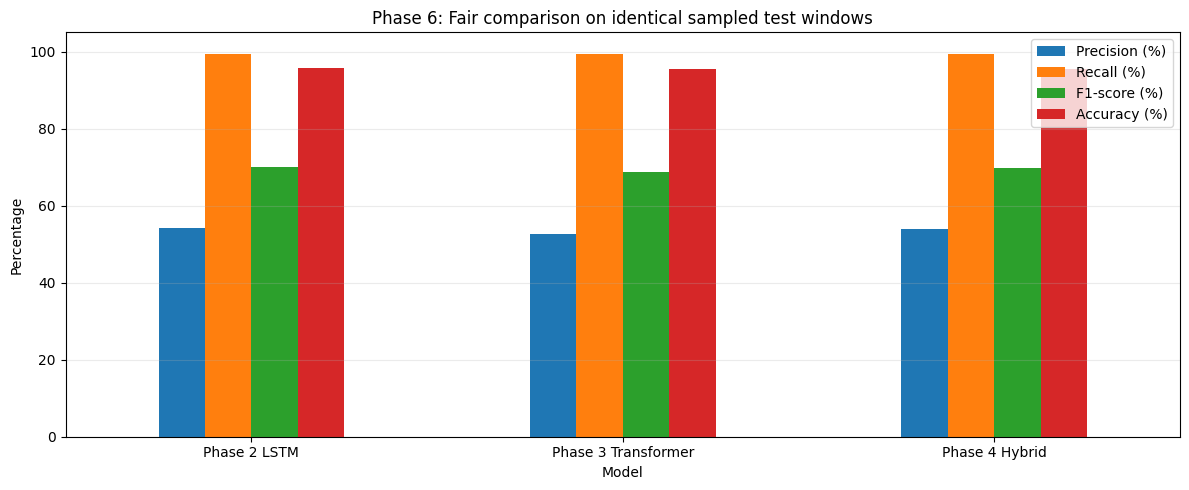

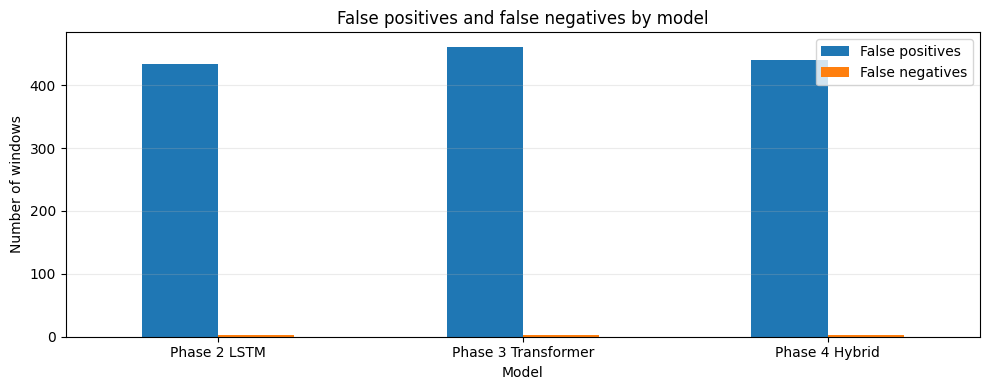

In [50]:
metric_names = ['Precision (%)', 'Recall (%)', 'F1-score (%)', 'Accuracy (%)']
ax = results_df[metric_names].plot(kind='bar', figsize=(12, 5))
ax.set_title('Phase 6: Fair comparison on identical sampled test windows')
ax.set_ylabel('Percentage')
ax.set_xlabel('Model')
ax.set_ylim(0, 105)
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

ax = results_df[['False positives', 'False negatives']].plot(
    kind='bar', figsize=(10, 4)
)
ax.set_title('False positives and false negatives by model')
ax.set_ylabel('Number of windows')
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Event-wise detection rates

The event groups below are derived from the sampled event labels and Phase 1 window timestamps where available. This section first reports the total sampled event-positive windows detected. If the timestamp array is available, it also prints event-period counts based on dates.

In [51]:
event_rows = []
for name in models:
    y_pred = predictions[name]
    total_event = int(y_test_event.sum())
    detected_event = int(((y_test_event == 1) & (y_pred == 1)).sum())
    missed_event = int(((y_test_event == 1) & (y_pred == 0)).sum())
    event_rows.append({
        'Model': name,
        'Event-labelled windows': total_event,
        'Detected event windows': detected_event,
        'Missed event windows': missed_event,
        'Event-window detection rate (%)':
            (detected_event / total_event * 100) if total_event else np.nan
    })

event_summary = pd.DataFrame(event_rows)
display(event_summary.round(3))

if 'test_window_times' in data.files:
    print('Phase 1 contains test_window_times. The sampled test_idx can be mapped to timestamps for a date-wise event breakdown.')
    print('Timestamp sample shape:', data['test_window_times'].shape)
else:
    print('No test_window_times key found; only aggregate event-labelled evaluation is available here.')

,Model,Event-labelled windows,Detected event windows,Missed event windows,Event-window detection rate (%)
0,Phase 2 LSTM,516,513,3,99.419
1,Phase 3 Transformer,516,513,3,99.419
2,Phase 4 Hybrid,516,513,3,99.419


Phase 1 contains test_window_times. The sampled test_idx can be mapped to timestamps for a date-wise event breakdown.
Timestamp sample shape: (524836,)


## 11. Threshold sensitivity analysis

We evaluate each model at validation percentiles 95, 97, 98, 99 and 99.5. Thresholds are always computed from validation errors. This illustrates the trade-off between detecting more event windows and generating more false alarms.

In [52]:
percentiles = [95, 97, 98, 99, 99.5]
sensitivity_rows = []

for name in models:
    for percentile in percentiles:
        t = float(np.percentile(val_errors[name], percentile))
        metrics = evaluate_scores(test_errors[name], y_test_event, t)
        sensitivity_rows.append({
            'Model': name,
            'Validation percentile': percentile,
            'Threshold': t,
            'Precision (%)': metrics['Precision (%)'],
            'Recall (%)': metrics['Recall (%)'],
            'F1-score (%)': metrics['F1-score (%)'],
            'False positives': metrics['False positives'],
            'False negatives': metrics['False negatives'],
            'Anomaly rate (%)': metrics['Anomaly rate (%)']
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df.round(3))

,Model,Validation percentile,Threshold,Precision (%),Recall (%),F1-score (%),False positives,False negatives,Anomaly rate (%)
0,Phase 2 LSTM,95.0,2.968,54.000,99.419,69.986,437,3,9.50
1,Phase 2 LSTM,97.0,3.042,54.000,99.419,69.986,437,3,9.50
2,Phase 2 LSTM,98.0,3.176,54.057,99.419,70.034,436,3,9.49
3,Phase 2 LSTM,99.0,3.241,54.171,99.419,70.130,434,3,9.47
4,Phase 2 LSTM,99.5,6.274,9.524,1.163,2.073,57,510,0.63
5,Phase 3 Transformer,95.0,1.762,46.727,99.612,63.614,586,2,11.00
6,Phase 3 Transformer,97.0,1.853,49.232,99.419,65.854,529,3,10.42
7,Phase 3 Transformer,98.0,1.887,49.232,99.419,65.854,529,3,10.42
8,Phase 3 Transformer,99.0,1.964,52.669,99.419,68.859,461,3,9.74
9,Phase 3 Transformer,99.5,5.899,9.524,1.163,2.073,57,510,0.63


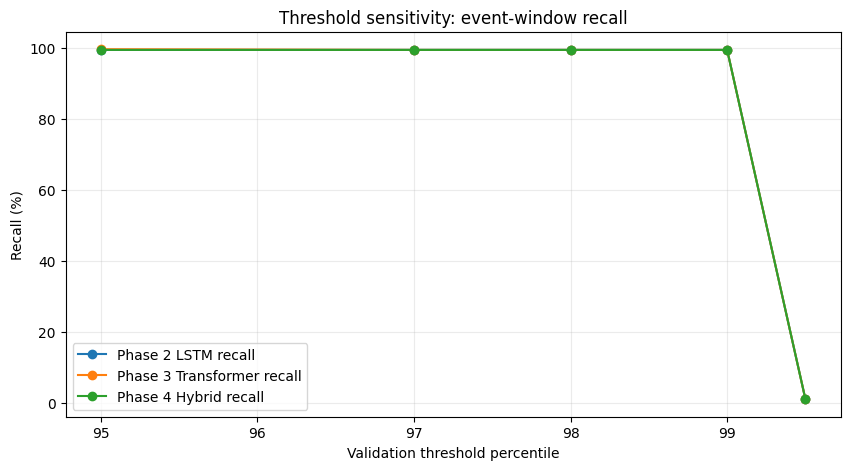

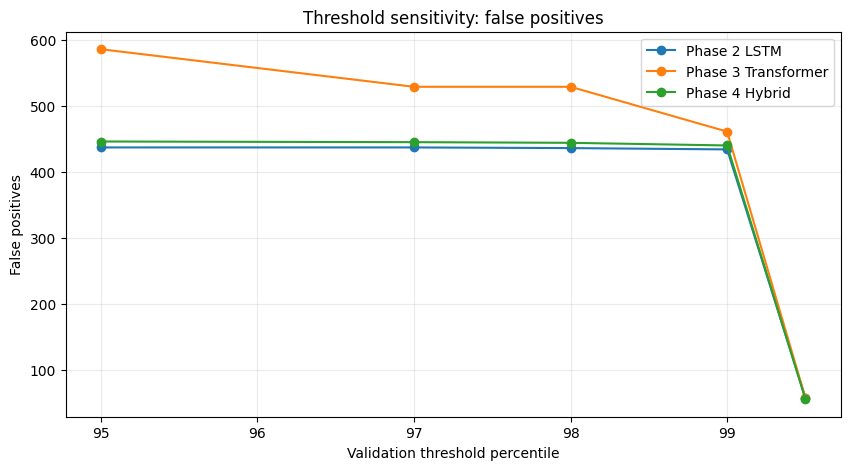

In [53]:
plt.figure(figsize=(10, 5))
for name in models:
    subset = sensitivity_df[sensitivity_df['Model'] == name]
    plt.plot(
        subset['Validation percentile'],
        subset['Recall (%)'],
        marker='o',
        label=name + ' recall'
    )
plt.xlabel('Validation threshold percentile')
plt.ylabel('Recall (%)')
plt.title('Threshold sensitivity: event-window recall')
plt.grid(alpha=0.25)
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
for name in models:
    subset = sensitivity_df[sensitivity_df['Model'] == name]
    plt.plot(
        subset['Validation percentile'],
        subset['False positives'],
        marker='o',
        label=name
    )
plt.xlabel('Validation threshold percentile')
plt.ylabel('False positives')
plt.title('Threshold sensitivity: false positives')
plt.grid(alpha=0.25)
plt.legend()
plt.show()

## 12. Compare reconstruction-error distributions

This helps show how the models' validation and test error distributions differ. The vertical line for each model is its own validation-derived 99th-percentile threshold.

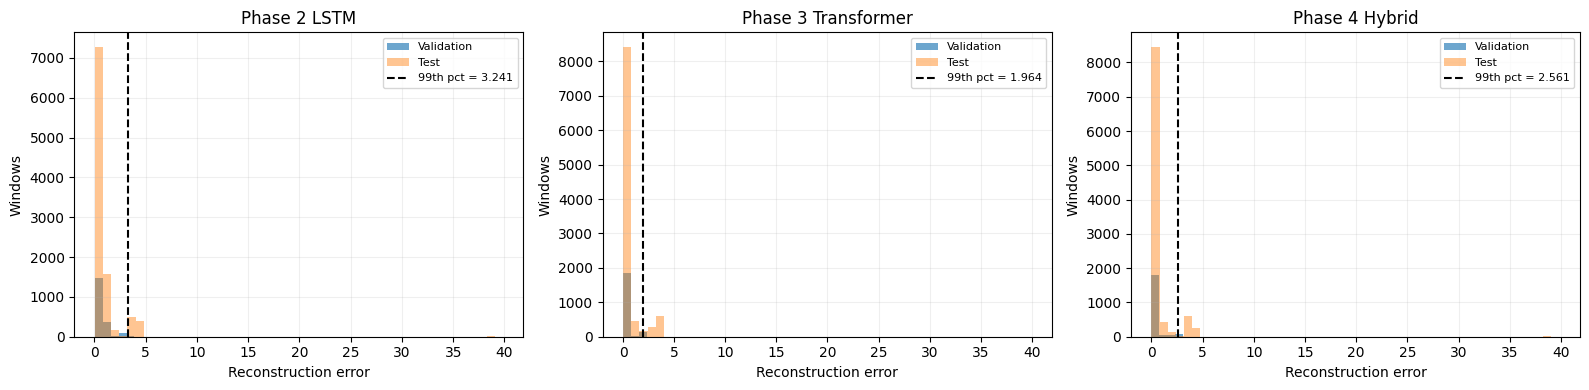

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes, models):
    ax.hist(val_errors[name], bins=50, alpha=0.65, label='Validation')
    ax.hist(test_errors[name], bins=50, alpha=0.45, label='Test')
    ax.axvline(thresholds[name], linestyle='--', color='black',
               label=f"99th pct = {thresholds[name]:.3f}")
    ax.set_title(name)
    ax.set_xlabel('Reconstruction error')
    ax.set_ylabel('Windows')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 13. Optional: Monte Carlo threshold calibration for the hybrid model

This uses the same stochastic scoring procedure on validation and test data. It is an optional, more consistent uncertainty-aware comparison. It can take longer because the hybrid model is evaluated repeatedly.

In [55]:
RUN_HYBRID_MC = True
MC_RUNS_PHASE6 = 10
MC_VAL_SIZE = min(2000, len(X_val))
MC_TEST_SIZE = min(2000, len(X_test))

if RUN_HYBRID_MC:
    def mc_reconstruction_error(model, X, runs=10):
        scores = []
        for r in range(runs):
            recon = model(X, training=True).numpy()
            scores.append(np.mean(np.abs(X - recon), axis=(1, 2)))
        return np.stack(scores, axis=0)

    hybrid_mc_val = mc_reconstruction_error(
        hybrid_model, X_val[:MC_VAL_SIZE], MC_RUNS_PHASE6
    )
    hybrid_mc_test = mc_reconstruction_error(
        hybrid_model, X_test[:MC_TEST_SIZE], MC_RUNS_PHASE6
    )

    hybrid_mc_val_mean = hybrid_mc_val.mean(axis=0)
    hybrid_mc_test_mean = hybrid_mc_test.mean(axis=0)
    hybrid_mc_threshold = float(np.percentile(hybrid_mc_val_mean, 99))
    hybrid_mc_pred = (hybrid_mc_test_mean > hybrid_mc_threshold).astype(int)
    hybrid_mc_y = y_test_event[:MC_TEST_SIZE]

    hybrid_mc_metrics = evaluate_scores(
        hybrid_mc_test_mean, hybrid_mc_y, hybrid_mc_threshold
    )

    print('Hybrid MC validation threshold:', hybrid_mc_threshold)
    print('Hybrid MC metrics on matching test subset:')
    display(pd.DataFrame([hybrid_mc_metrics]).round(3))
    print('Mean MC uncertainty (test):',
          float(hybrid_mc_test.std(axis=0).mean()))
else:
    print('Skipped. Set RUN_HYBRID_MC=True to run this optional experiment.')

Hybrid MC validation threshold: 2.556631088256836
Hybrid MC metrics on matching test subset:


,Precision (%),Recall (%),F1-score (%),Accuracy (%),False positives,False negatives,True positives,True negatives,Predicted anomalies,Anomaly rate (%)
0,51.579,100.0,68.056,95.4,92,0,98,1810,190,9.5


Mean MC uncertainty (test): 0.005022722762078047


## 14. Final comparison summary and research interpretation

This section selects the model with the highest F1-score in the primary 99th-percentile validation-threshold comparison. The best model is selected by the sampled test F1 for descriptive comparison only; for a final unbiased model-selection claim, a separate untouched test set or nested validation protocol would be preferable.

In [56]:
best_model_by_f1 = results_df['F1-score (%)'].idxmax()
print('Highest sampled-test F1 model:', best_model_by_f1)
print('F1-score:', round(float(results_df.loc[best_model_by_f1, 'F1-score (%)']), 3), '%')

print('\nPrimary comparison:')
display(results_df[[
    'Precision (%)', 'Recall (%)', 'F1-score (%)', 'Accuracy (%)',
    'False positives', 'False negatives'
]].round(3))

print('\nInterpretation reminders:')
print('- Higher recall means more event-labelled windows were detected.')
print('- False positives are normal-labelled windows flagged as anomalous.')
print('- These are event-period detection metrics, not advance-warning metrics.')
print('- A hybrid model is not automatically superior because it combines two architectures.')

Highest sampled-test F1 model: Phase 2 LSTM
F1-score: 70.13 %

Primary comparison:


,Precision (%),Recall (%),F1-score (%),Accuracy (%),False positives,False negatives
Model,,,,,,
Phase 2 LSTM,54.171,99.419,70.130,95.63,434.0,3.0
Phase 3 Transformer,52.669,99.419,68.859,95.36,461.0,3.0
Phase 4 Hybrid,53.830,99.419,69.843,95.57,440.0,3.0



Interpretation reminders:
- Higher recall means more event-labelled windows were detected.
- False positives are normal-labelled windows flagged as anomalous.
- These are event-period detection metrics, not advance-warning metrics.
- A hybrid model is not automatically superior because it combines two architectures.


## 15. Save Phase 6 outputs

In [57]:
results_df.to_csv(os.path.join(OUT_DIR, 'phase6_model_comparison.csv'))
threshold_table.to_csv(os.path.join(OUT_DIR, 'phase6_thresholds.csv'), index=False)
sensitivity_df.to_csv(os.path.join(OUT_DIR, 'phase6_threshold_sensitivity.csv'), index=False)
event_summary.to_csv(os.path.join(OUT_DIR, 'phase6_event_summary.csv'), index=False)

error_arrays = {}
for name in models:
    safe = name.lower().replace(' ', '_').replace('-', '_')
    error_arrays[f'{safe}_val_errors'] = val_errors[name]
    error_arrays[f'{safe}_test_errors'] = test_errors[name]
    error_arrays[f'{safe}_predictions'] = predictions[name]

np.savez_compressed(
    os.path.join(OUT_DIR, 'phase6_reconstruction_errors_and_predictions.npz'),
    **error_arrays
)

phase6_metadata = {
    'phase': 6,
    'project': 'DeepSense-X',
    'dataset': 'MetroPT-3',
    'seed': SEED,
    'sample_sizes': {
        'train': int(len(X_train)),
        'validation': int(len(X_val)),
        'test': int(len(X_test))
    },
    'threshold_percentile': 99,
    'thresholds': {k: float(v) for k, v in thresholds.items()},
    'best_sampled_test_f1_model': str(best_model_by_f1),
    'metrics': results_df.reset_index().to_dict(orient='records'),
    'notes': [
        'All three models use identical sampled validation and test windows.',
        'Each threshold is calibrated on that model validation reconstruction errors.',
        'Event-period detection does not establish advance failure prediction.',
        'Results are sampled-window experiments, not full-test-set results.'
    ]
}
with open(os.path.join(OUT_DIR, 'phase6_metadata.json'), 'w') as f:
    json.dump(phase6_metadata, f, indent=2)

print('Phase 6 outputs saved to:', OUT_DIR)

Phase 6 outputs saved to: /content/drive/MyDrive/DeepSense_X_MetroPT3/phase6


## 16. Verify saved outputs

In [58]:
expected = [
    'phase6_model_comparison.csv',
    'phase6_thresholds.csv',
    'phase6_threshold_sensitivity.csv',
    'phase6_event_summary.csv',
    'phase6_reconstruction_errors_and_predictions.npz',
    'phase6_metadata.json'
]
for filename in expected:
    path = os.path.join(OUT_DIR, filename)
    print(('OK   ' if os.path.exists(path) else 'MISSING ') + filename)

OK   phase6_model_comparison.csv
OK   phase6_thresholds.csv
OK   phase6_threshold_sensitivity.csv
OK   phase6_event_summary.csv
OK   phase6_reconstruction_errors_and_predictions.npz
OK   phase6_metadata.json


In [59]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
import os

PROJECT_DIR = "/content/drive/MyDrive/DeepSense_X_MetroPT3"

print("Project exists:", os.path.exists(PROJECT_DIR))
print("\nProject contents:")

for item in os.listdir(PROJECT_DIR):
    print(item)

Project exists: True

Project contents:
raw
processed
artifacts
MetroPT3(AirCompressor).csv
.ipynb_checkpoints
notebooks
phase5
phase6


In [61]:
for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d not in ["__pycache__", ".ipynb_checkpoints"]]

    level = root.replace(PROJECT_DIR, "").count(os.sep)
    if level > 2:
        continue

    print("\n" + os.path.relpath(root, PROJECT_DIR))
    for file in files:
        print("  ", file)


.
   MetroPT3(AirCompressor).csv

raw
   MetroPT3(AirCompressor).csv
   metropt_raw.csv

processed
   metropt3_phase1_windows.npz
   metropt3_phase2_lstm_results.npz
   metropt3_phase3_transformer_results.npz
   metropt3_phase4_hybrid_results.npz

artifacts
   metropt3_standard_scaler.joblib
   metropt3_baseline_scaler.joblib
   phase1_metadata.json
   feature_columns.json
   phase2_lstm_autoencoder.keras
   phase2_lstm_autoencoder_final.keras
   phase2_lstm_metadata.json
   phase3_transformer_autoencoder_best.keras
   phase3_transformer_autoencoder_final.keras
   phase3_transformer_metadata.json
   phase4_hybrid_autoencoder_best.keras
   phase4_hybrid_lstm_transformer_final.keras
   phase4_hybrid_metadata.json

notebooks
   DeepSense_X_Phase1_MetroPT3.ipynb
   DeepSense_X_Phase2_LSTM_Autoencoder.ipynb
   DeepSense_X_Phase3_Transformer_Autoencoder.ipynb
   DeepSense_X_Phase4_Hybrid_LSTM_Transformer.ipynb
   DeepSense_X_Phase5_Uncertainty_Explainability_Robustness.ipynb
   DeepSense_X_

In [62]:
import os

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]

    print(f"\n📁 {os.path.relpath(root, PROJECT_DIR)}")

    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"   {file}  ({size_mb:.2f} MB)")



📁 .
   MetroPT3(AirCompressor).csv  (208.19 MB)

📁 raw
   MetroPT3(AirCompressor).csv  (208.19 MB)
   metropt_raw.csv  (133.00 MB)

📁 processed
   metropt3_phase1_windows.npz  (42.20 MB)
   metropt3_phase2_lstm_results.npz  (0.06 MB)
   metropt3_phase3_transformer_results.npz  (0.06 MB)
   metropt3_phase4_hybrid_results.npz  (0.06 MB)

📁 artifacts
   metropt3_standard_scaler.joblib  (0.00 MB)
   metropt3_baseline_scaler.joblib  (0.00 MB)
   phase1_metadata.json  (0.00 MB)
   feature_columns.json  (0.00 MB)
   phase2_lstm_autoencoder.keras  (0.26 MB)
   phase2_lstm_autoencoder_final.keras  (0.26 MB)
   phase2_lstm_metadata.json  (0.00 MB)
   phase3_transformer_autoencoder_best.keras  (0.21 MB)
   phase3_transformer_autoencoder_final.keras  (0.21 MB)
   phase3_transformer_metadata.json  (0.00 MB)
   phase4_hybrid_autoencoder_best.keras  (0.42 MB)
   phase4_hybrid_lstm_transformer_final.keras  (0.42 MB)
   phase4_hybrid_metadata.json  (0.00 MB)

📁 notebooks
   DeepSense_X_Phase1_MetroPT3

In [63]:
gitignore_content = """
# Original datasets
raw/
MetroPT3(AirCompressor).csv
metropt_raw.csv

# Large processed data
processed/*.npz

# Trained model checkpoints
artifacts/*.keras
artifacts/*.h5

# Large experiment arrays
phase5/*.npz
phase6/*.npz

# Python and Jupyter temporary files
__pycache__/
*.pyc
.ipynb_checkpoints/
.DS_Store

# Environment and secrets
.env
*.token
"""

gitignore_path = os.path.join(PROJECT_DIR, ".gitignore")

with open(gitignore_path, "w") as f:
    f.write(gitignore_content)

print(".gitignore created successfully!")

.gitignore created successfully!


In [67]:
README = r"""
# DeepSense-X

### An Explainable and Uncertainty-Aware Hybrid LSTM–Transformer Framework for Industrial Anomaly Detection and Predictive Maintenance

DeepSense-X explores deep-learning-based anomaly detection for industrial air compressor systems using the MetroPT-3 dataset.

## Models
1. LSTM Autoencoder
2. Transformer Autoencoder
3. Hybrid LSTM–Transformer Autoencoder

## Project Phases

| Phase | Description |
|---|---|
| Phase 1 | Data preprocessing and window generation |
| Phase 2 | LSTM Autoencoder |
| Phase 3 | Transformer Autoencoder |
| Phase 4 | Hybrid LSTM–Transformer |
| Phase 5 | Uncertainty, explainability and robustness |
| Phase 6 | Final experimental evaluation |

## Dataset

MetroPT-3 dataset:
https://archive.ics.uci.edu/dataset/791/metropt+3+dataset

The original dataset is not included in this repository.

## Final Experimental Results

| Model | Precision | Recall | F1-score | Accuracy |
|---|---:|---:|---:|---:|
| LSTM Autoencoder | 54.17% | 99.42% | 70.13% | 95.63% |
| Transformer Autoencoder | 52.67% | 99.42% | 68.86% | 95.36% |
| Hybrid LSTM–Transformer | 53.83% | 99.42% | 69.84% | 95.57% |

Results are based on a sampled 10,000-window test set. Event-period detection does not establish advance failure prediction.

## Explainability and Uncertainty

Phase 5 includes:
- Monte Carlo uncertainty estimation
- Sensor perturbation importance
- Local sensor explanations
- Missing sensor experiments
- Noise and sensor drift experiments

Perturbation importance measures model sensitivity, not causality.

## Technology Stack

- Python
- TensorFlow / Keras
- NumPy
- Pandas
- Scikit-learn
- Matplotlib
- Google Colab

## Repository Structure

- `notebooks/` – Six project notebooks
- `artifacts/` – Model metadata and preprocessing artifacts
- `phase5/` – Explainability and robustness results
- `phase6/` – Final evaluation results

Large datasets, model checkpoints and generated arrays are excluded from the initial GitHub upload.

## How to Run

1. Clone this repository.
2. Download the MetroPT-3 dataset from UCI.
3. Open the notebooks in Google Colab.
4. Mount Google Drive and configure the dataset path.
5. Run notebooks sequentially from Phase 1 to Phase 6.

## Author

**Udit Pattnayak**

Deep Learning | Anomaly Detection | Predictive Maintenance
"""

with open(os.path.join(PROJECT_DIR, "README.md"), "w", encoding="utf-8") as f:
    f.write(README)

requirements = """numpy
pandas
scikit-learn
matplotlib
seaborn
tensorflow
keras
joblib
jupyter
"""

with open(os.path.join(PROJECT_DIR, "requirements.txt"), "w") as f:
    f.write(requirements)

print("README.md created successfully!")
print("requirements.txt created successfully!")

README.md created successfully!
requirements.txt created successfully!


In [68]:
print(open(os.path.join(PROJECT_DIR, "README.md")).read()[:500])


# DeepSense-X

### An Explainable and Uncertainty-Aware Hybrid LSTM–Transformer Framework for Industrial Anomaly Detection and Predictive Maintenance

DeepSense-X explores deep-learning-based anomaly detection for industrial air compressor systems using the MetroPT-3 dataset.

## Models
1. LSTM Autoencoder
2. Transformer Autoencoder
3. Hybrid LSTM–Transformer Autoencoder

## Project Phases

| Phase | Description |
|---|---|
| Phase 1 | Data preprocessing and window generation |
| Phase 2 | LSTM


In [69]:
!sudo apt-get update -qq
!sudo apt-get install gh -y -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../archives/gh_2.105.0_amd64.deb ...
Unpacking gh (2.105.0) over (2.103.2) ...
Setting up gh (2.105.0) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [70]:
import getpass
import subprocess

token = getpass.getpass("Enter GitHub token (hidden): ")

result = subprocess.run(
    ["gh", "auth", "login", "--hostname", "github.com", "--with-token"],
    input=token,
    text=True,
    capture_output=True
)

token = None

if result.returncode == 0:
    print("GitHub authentication successful!")
else:
    print("Authentication failed:", result.stderr)

Enter GitHub token (hidden): ··········
GitHub authentication successful!


## Phase 6 completion checklist

- [ ] All three trained models loaded.
- [ ] Identical validation/test samples reproduced.
- [ ] Reconstruction errors calculated for all models.
- [ ] Separate validation thresholds calibrated.
- [ ] Metrics and confusion matrices generated.
- [ ] False positives and false negatives compared.
- [ ] Threshold sensitivity evaluated.
- [ ] Event-window detection compared.
- [ ] Optional hybrid Monte Carlo calibration completed.
- [ ] All outputs saved and verified.

### Important final-report limitation
The test sample was used for model comparison and threshold sensitivity reporting. If the same sample informed model selection, report these as exploratory sampled-test comparisons rather than a fully untouched final generalization estimate. Do not claim predictive lead time unless a separate temporal lead-time experiment is performed.